# OECD maritime CO₂ vs the Red Sea diversion

**What this notebook does.** It compares the top-down OECD monthly container-ship CO₂ series against the bottom-up distance increase observed in Climate TRACE container voyages during the Red Sea diversion (Case 2). The OECD data covers world-total emissions by vessel type; Climate TRACE gives per-voyage distances on the Asia → US lanes the project tracks.

**Why it matters.** Case 2 estimates extra transport emissions from ships rerouting around the Cape of Good Hope. The OECD series is an independent, top-down measurement. If the two are consistent — the global CO₂ rise is proportionally larger than the Asia → US distance rise, because the diversion affects Suez-routed lanes globally, not just US-bound ones — the Case 2 bottom-up numbers are plausible.

**Limitations.** The OECD series allocates emissions to the country of the operating company, not where ships sail, so it can only be compared globally, not by lane. It reports CO₂ only (not CO₂e). The data comes from one vintage; the OECD revised its methodology in May 2025.

**To run:** set `ANALYST_DATABASE_URL` in `analysis/.env`, then run all cells.

## 1. Setup

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import polars as pl

from shockt_analysis import core
from shockt_analysis.settings import get_settings

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(140)
pl.Config.set_float_precision(4)

DIVERSION_START = date(2023, 12, 1)

In [2]:
with core.connect(get_settings()) as conn:
    oecd = core.oecd_maritime_emissions(conn)
    transits = core.chokepoint_transits(conn)
    lanes = core.voyage_lanes(conn)
    loads = core.current_loads(
        conn,
        [
            "oecd_maritime_emissions",
            "portwatch_chokepoints",
            "climatetrace_voyages",
        ],
    )

print(f"OECD: {oecd.height} rows")
print(f"Chokepoint transits: {transits.height} rows")
print(f"Voyage lanes: {lanes.height} rows")
print()
loads

OECD: 900 rows
Chokepoint transits: 232 rows
Voyage lanes: 1100 rows



dataset,partitions,latest_load,code_versions
str,i64,str,str
"""climatetrace_voyages""",5,"""2026-10-12 22:52:15.201059+00""","""20b5845"""
"""oecd_maritime_emissions""",4,"""2026-10-29 20:49:06.715992+00""","""565063f"""
"""portwatch_chokepoints""",20,"""2026-10-14 04:46:54.456248+00""","""706c683"""


## 2. OECD container CO₂: monthly time series

World-total monthly CO₂ for container ships and all vessels, from the OECD experimental maritime transport dataset.

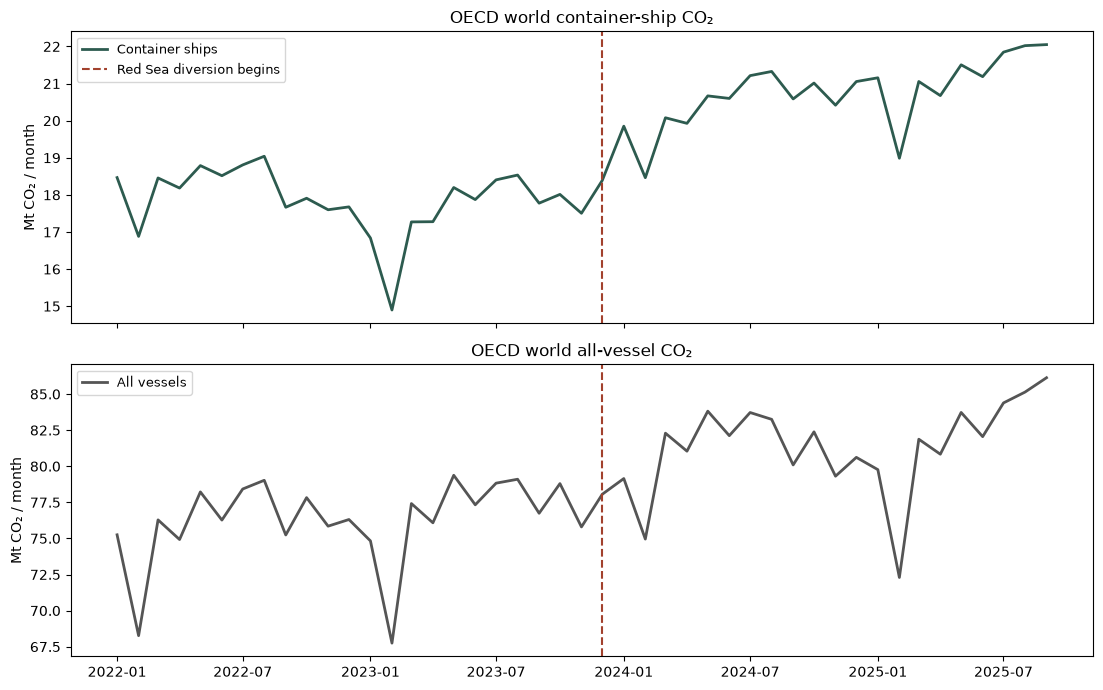

In [3]:
container = oecd.filter(pl.col("vessel") == "CONTAINER")
all_vessels = oecd.filter(pl.col("vessel") == "ALL_VESSELS")

# Parse month strings to dates for plotting
container = container.with_columns(
    pl.col("month").str.strptime(pl.Date, "%Y-%m").alias("date"),
)
all_vessels = all_vessels.with_columns(
    pl.col("month").str.strptime(pl.Date, "%Y-%m").alias("date"),
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

ax1.plot(
    container["date"].to_list(),
    (container["co2_t"] / 1e6).to_list(),
    color="#2d5b4f",
    lw=2,
    label="Container ships",
)
ax1.axvline(DIVERSION_START, color="#a2412d", ls="--", lw=1.5, label="Red Sea diversion begins")
ax1.set_ylabel("Mt CO₂ / month")
ax1.set_title("OECD world container-ship CO₂")
ax1.legend(fontsize=9)

ax2.plot(
    all_vessels["date"].to_list(),
    (all_vessels["co2_t"] / 1e6).to_list(),
    color="#555",
    lw=2,
    label="All vessels",
)
ax2.axvline(DIVERSION_START, color="#a2412d", ls="--", lw=1.5)
ax2.set_ylabel("Mt CO₂ / month")
ax2.set_title("OECD world all-vessel CO₂")
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()

In [4]:
# Year-over-year: mean monthly container CO2 by year
yearly = (
    container.with_columns(
        pl.col("month").str.slice(0, 4).alias("year"),
    )
    .group_by("year")
    .agg(
        (pl.col("co2_t").sum() / 1e6).alias("annual_mt"),
        (pl.col("co2_t").mean() / 1e6).alias("mean_monthly_mt"),
        pl.len().alias("months"),
    )
    .sort("year")
)

print("Container CO₂ by year (world total):")
yearly

Container CO₂ by year (world total):


year,annual_mt,mean_monthly_mt,months
str,f64,f64,u32
"""2022""",217.9974,18.1664,12
"""2023""",210.9847,17.5821,12
"""2024""",245.2044,20.4337,12
"""2025""",190.4884,21.1654,9


In [5]:
# Same-month 2023 vs 2024 comparison
c23 = container.filter(
    pl.col("month").str.starts_with("2023"),
).select(
    pl.col("month").str.slice(5, 2).alias("mm"),
    (pl.col("co2_t") / 1e6).alias("mt_2023"),
)
c24 = container.filter(
    pl.col("month").str.starts_with("2024"),
).select(
    pl.col("month").str.slice(5, 2).alias("mm"),
    (pl.col("co2_t") / 1e6).alias("mt_2024"),
)
yoy = (
    c23.join(c24, on="mm")
    .with_columns(
        ((pl.col("mt_2024") / pl.col("mt_2023") - 1) * 100).round(1).alias("pct_change"),
    )
    .sort("mm")
)

print("Same-month container CO₂ change, 2023 → 2024:")
yoy

Same-month container CO₂ change, 2023 → 2024:


mm,mt_2023,mt_2024,pct_change
str,f64,f64,f64
"""01""",16.8382,19.8521,17.9000
"""02""",14.8980,18.4633,23.9000
"""03""",17.2719,20.0787,16.3000
"""04""",17.2777,19.9284,15.3000
"""05""",18.1989,20.6684,13.6000
"""06""",17.8741,20.5997,15.2000
"""07""",18.4051,21.2139,15.3000
"""08""",18.5346,21.3267,15.1000
"""09""",17.7772,20.5863,15.8000


## 3. Chokepoint transits: confirmation of rerouting

PortWatch daily transit counts at the Suez Canal, Bab el-Mandeb and the Cape of Good Hope.

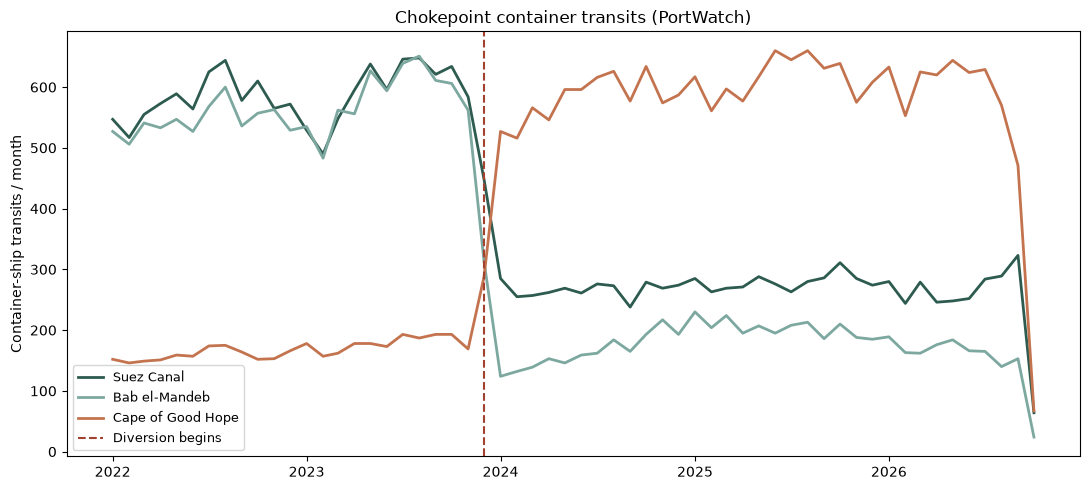

In [6]:
suez = transits.filter(pl.col("chokepoint_id") == "chokepoint1")
bab = transits.filter(pl.col("chokepoint_id") == "chokepoint4")
cape = transits.filter(pl.col("chokepoint_id") == "chokepoint7")

fig, ax = plt.subplots(figsize=(11, 5))
for df, label, color in [
    (suez, "Suez Canal", "#2d5b4f"),
    (bab, "Bab el-Mandeb", "#7ca8a0"),
    (cape, "Cape of Good Hope", "#c4734f"),
]:
    ax.plot(
        df["month"].to_list(),
        df["n_container"].to_list(),
        lw=2,
        label=label,
        color=color,
    )
ax.axvline(DIVERSION_START, color="#a2412d", ls="--", lw=1.5, label="Diversion begins")
ax.set_ylabel("Container-ship transits / month")
ax.set_title("Chokepoint container transits (PortWatch)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

In [7]:
pre = date(2023, 6, 1)
pre_end = date(2023, 11, 1)
post = date(2024, 1, 1)
post_end = date(2024, 6, 1)

transit_change: list[dict[str, object]] = []
for df, name in [(suez, "Suez"), (bab, "Bab el-Mandeb"), (cape, "Cape")]:
    pre_avg = df.filter(
        (pl.col("month") >= pre) & (pl.col("month") <= pre_end),
    )["n_container"].mean()
    post_avg = df.filter(
        (pl.col("month") >= post) & (pl.col("month") <= post_end),
    )["n_container"].mean()
    transit_change.append(
        {
            "chokepoint": name,
            "pre_avg": round(pre_avg),
            "post_avg": round(post_avg),
            "pct_change": round((post_avg / pre_avg - 1) * 100),
        }
    )

print("Container transits, Jun-Nov 2023 vs Jan-Jun 2024:")
pl.DataFrame(transit_change)

Container transits, Jun-Nov 2023 vs Jan-Jun 2024:


chokepoint,pre_avg,post_avg,pct_change
str,i64,i64,i64
"""Suez""",622,265,-57
"""Bab el-Mandeb""",610,142,-77
"""Cape""",185,558,202


## 4. Voyage distances: bottom-up distance increase

Climate TRACE container-ship voyages from Asian origins to the US, which pass through or near the affected Suez / Bab el-Mandeb route.

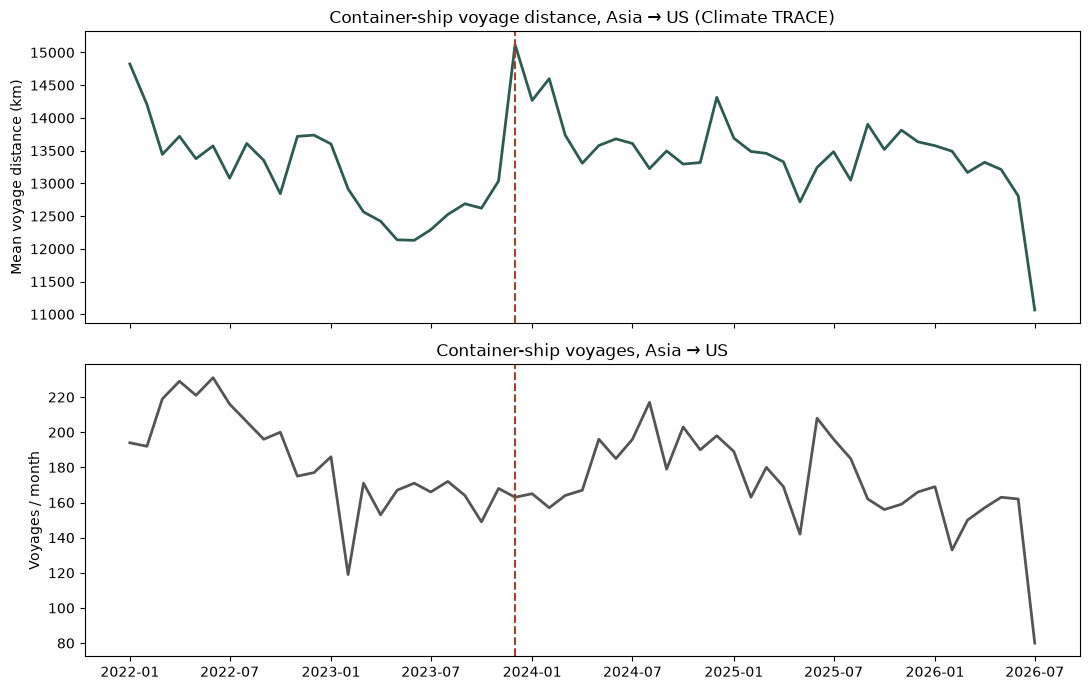

In [8]:
asia = lanes.filter(pl.col("origin_region") == "asia")
asia_monthly = (
    asia.group_by("month")
    .agg(
        pl.col("n_voyages").sum(),
        (pl.col("total_distance_km").sum() / pl.col("n_voyages").sum()).alias("mean_km"),
    )
    .sort("month")
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax1.plot(
    asia_monthly["month"].to_list(),
    asia_monthly["mean_km"].to_list(),
    color="#2d5b4f",
    lw=2,
)
ax1.axvline(DIVERSION_START, color="#a2412d", ls="--", lw=1.5)
ax1.set_ylabel("Mean voyage distance (km)")
ax1.set_title(
    "Container-ship voyage distance, Asia → US (Climate TRACE)",
)

ax2.plot(
    asia_monthly["month"].to_list(),
    asia_monthly["n_voyages"].to_list(),
    color="#555",
    lw=2,
)
ax2.axvline(DIVERSION_START, color="#a2412d", ls="--", lw=1.5)
ax2.set_ylabel("Voyages / month")
ax2.set_title("Container-ship voyages, Asia → US")
plt.tight_layout()
plt.show()

In [9]:
dist_pre = asia_monthly.filter(
    (pl.col("month") >= pre) & (pl.col("month") <= pre_end),
)
dist_post = asia_monthly.filter(
    (pl.col("month") >= post) & (pl.col("month") <= post_end),
)
pre_km = dist_pre["mean_km"].mean()
post_km = dist_post["mean_km"].mean()
dist_pct = (post_km / pre_km - 1) * 100

pre_voy = dist_pre["n_voyages"].mean()
post_voy = dist_post["n_voyages"].mean()

print("Asia → US container voyages, Jun-Nov 2023 vs Jan-Jun 2024:")
print(f"  Mean distance: {pre_km:,.0f} → {post_km:,.0f} km ({dist_pct:+.1f}%)")
print(f"  Voyages/month: {pre_voy:.0f} → {post_voy:.0f}")

Asia → US container voyages, Jun-Nov 2023 vs Jan-Jun 2024:
  Mean distance: 12,549 → 13,862 km (+10.5%)
  Voyages/month: 165 → 172


## 5. Comparison: top-down vs bottom-up

In [10]:
oecd_pre = container.filter(
    (pl.col("date") >= pre) & (pl.col("date") <= pre_end),
)["co2_t"].mean()
oecd_post = container.filter(
    (pl.col("date") >= post) & (pl.col("date") <= post_end),
)["co2_t"].mean()
oecd_pct = (oecd_post / oecd_pre - 1) * 100

# 2022 → 2023 baseline change (pre-diversion trend)
oecd_22 = container.filter(
    pl.col("month").str.starts_with("2022"),
)["co2_t"].mean()
oecd_23 = container.filter(
    pl.col("month").str.starts_with("2023"),
)["co2_t"].mean()
baseline_pct = (oecd_23 / oecd_22 - 1) * 100

comparison = pl.DataFrame(
    {
        "measure": [
            "OECD container CO₂ (world)",
            "Climate TRACE distance (Asia→US)",
            "OECD baseline trend (2022→2023)",
        ],
        "pre_diversion": [
            f"{oecd_pre / 1e6:.1f} Mt/mo",
            f"{pre_km:,.0f} km",
            f"{oecd_22 / 1e6:.1f} Mt/mo",
        ],
        "post_diversion": [
            f"{oecd_post / 1e6:.1f} Mt/mo",
            f"{post_km:,.0f} km",
            f"{oecd_23 / 1e6:.1f} Mt/mo",
        ],
        "change_pct": [
            round(oecd_pct, 1),
            round(dist_pct, 1),
            round(baseline_pct, 1),
        ],
    }
)
comparison

measure,pre_diversion,post_diversion,change_pct
str,str,str,f64
"""OECD container CO₂ (world)""","""18.0 Mt/mo""","""19.9 Mt/mo""",10.6000
"""Climate TRACE distance (Asia→U…","""12,549 km""","""13,862 km""",10.5000
"""OECD baseline trend (2022→2023…","""18.2 Mt/mo""","""17.6 Mt/mo""",-3.2000


## 6. Findings

In [11]:
findings = [
    f"OECD container-ship CO₂ rose {oecd_pct:+.0f}% between the "
    "pre-diversion period (Jun-Nov 2023) and post-diversion "
    "(Jan-Jun 2024), from "
    f"{oecd_pre / 1e6:.1f} to {oecd_post / 1e6:.1f} Mt/month.",
    f"The pre-diversion trend was {baseline_pct:+.1f}% (2022→2023), "
    "so roughly "
    f"{oecd_pct - baseline_pct:+.0f} percentage points of the "
    "2023→2024 increase is above trend.",
    "Chokepoint transits confirm the rerouting: Suez container "
    f"transits fell {transit_change[0]['pct_change']}%, Bab el-Mandeb "
    f"{transit_change[1]['pct_change']}%, while Cape of Good Hope "
    f"rose {transit_change[2]['pct_change']}%.",
    f"Bottom-up voyage distances (Asia→US, Climate TRACE) rose "
    f"{dist_pct:+.1f}%, from {pre_km:,.0f} to {post_km:,.0f} km.",
    "The raw pre/post CO₂ increase (+11%) and distance increase "
    "(+10.5%) are nearly identical, but the comparison windows have "
    "different seasonality. Adjusting for the pre-diversion trend "
    f"({baseline_pct:+.1f}%), the above-trend CO₂ increase is "
    f"~{oecd_pct - baseline_pct:.0f} pp — larger than the distance "
    "rise because the OECD is global (all Suez-routed lanes, not "
    "just Asia→US) and includes demand and fleet changes.",
    "The two are consistent: a ~10% distance rise on Asia→US, "
    "combined with similar or larger rises on Europe- and "
    "Africa-bound lanes the project doesn't track, plausibly "
    f"produces the observed ~{oecd_pct - baseline_pct:.0f} pp "
    "above-trend global CO₂ rise.",
]
for i, f in enumerate(findings, 1):
    print(f"{i}. {f}")

1. OECD container-ship CO₂ rose +11% between the pre-diversion period (Jun-Nov 2023) and post-diversion (Jan-Jun 2024), from 18.0 to 19.9 Mt/month.
2. The pre-diversion trend was -3.2% (2022→2023), so roughly +14 percentage points of the 2023→2024 increase is above trend.
3. Chokepoint transits confirm the rerouting: Suez container transits fell -57%, Bab el-Mandeb -77%, while Cape of Good Hope rose 202%.
4. Bottom-up voyage distances (Asia→US, Climate TRACE) rose +10.5%, from 12,549 to 13,862 km.
5. The raw pre/post CO₂ increase (+11%) and distance increase (+10.5%) are nearly identical, but the comparison windows have different seasonality. Adjusting for the pre-diversion trend (-3.2%), the above-trend CO₂ increase is ~14 pp — larger than the distance rise because the OECD is global (all Suez-routed lanes, not just Asia→US) and includes demand and fleet changes.
6. The two are consistent: a ~10% distance rise on Asia→US, combined with similar or larger rises on Europe- and Africa-bou